# Conjunto de datos - matrículas sobre recortes de vehículos

En este cuaderno auxiliar se prepara el conjunto de datos con el que se entrena el detector de matrículas de la segunda parte de la práctica.

El detector de matrículas no trabaja sobre la foto completa, sino sobre los vehículos que encuentra el detector del primer módulo (RT-DETRv4-L). En la foto completa una matrícula ocupa muy pocos píxeles, y al reducir la imagen a la entrada del modelo (640 × 640) prácticamente desaparece. En el recorte de un vehículo, en cambio, la matrícula ocupa una parte mucho mayor de la imagen. Además, así el detector solo busca matrículas donde puede haberlas (sobre un vehículo).

## Proceso

Partiendo únicamente de las fotos y sus anotaciones, se siguen estos pasos:

- **Vehículos:** se pasa cada foto por RT-DETRv4-L con los pesos de COCO, buscando solo coches, motos, autobuses y camiones.
- **Recortes:** cada vehículo se recorta con un margen alrededor, descartando los recortes demasiado alargados.
- **Matrículas:** cada matrícula anotada se asigna a los recortes que la contienen (al menos en un 50%), con sus coordenadas relativas al recorte.
- **Reparto:** las fotos se reparten al azar entre entrenamiento, test y validación (70 / 15 / 15). Todos los recortes de una foto van al mismo conjunto, para no evaluar con vehículos que el modelo ya ha visto al entrenar.

El resultado se guarda en `data/vehicles/`, con el mismo formato de anotación que el conjunto de datos original.

## Índice

1. [Preparación](#1-preparación)
    - [1.1 Configuración](#11-configuración)
2. [_Dataset_ original](#2-dataset-original)
3. [Detector de vehículos](#3-detector-de-vehículos)
4. [Recortes de los vehículos](#4-recortes-de-los-vehículos)
5. [Matrículas de cada recorte](#5-matrículas-de-cada-recorte)
6. [Reparto en entrenamiento, test y validación](#6-reparto-en-entrenamiento-test-y-validación)
7. [Resultados](#7-resultados)

## 1. Preparación

### 1.1 Configuración

In [1]:
import json
import random
import shutil
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

sys.path.insert(0, "..")
from common.detectors import ObjectDetector
from common.paths import DATASET, PLATES_DATA

Rutas del conjunto de datos original (con las carpetas `images/` y `annotations/`) y del conjunto de datos de recortes que se genera. Las rutas comunes a todos los cuadernos están en [`common/paths.py`](../common/paths.py):

In [2]:
SRC_IMAGES = DATASET / "images"
SRC_ANNOTATIONS = DATASET / "annotations"
OUT = PLATES_DATA
VEHICLES_JSON = OUT / "vehicles.json"

OUT.mkdir(parents=True, exist_ok=True)

Parámetros del proceso:

- `VEHICLE_LABELS`: clases de COCO que se consideran vehículos, en el orden en que las devuelve el modelo: `car` (2), `motorcycle` (3), `bus` (5) y `truck` (7).
- `VEHICLE_CONF`: confianza mínima de un vehículo para recortarlo.
- `NMS_IOU`: solapamiento (IoU) a partir del cual dos detecciones se consideran duplicadas. Se descartan duplicados con NMS.
- `MARGIN`: margen que se añade alrededor de cada vehículo, en proporción a su tamaño, para no cortar una matrícula que sobresalga de la caja.
- `MAX_RATIO`: máximo _aspect ratio_. Los vehículos con proporciones más alargadas suelen estar cortados por el borde de la foto.
- `MIN_IOA`: parte mínima de una matrícula que debe quedar dentro de un recorte para anotarla (50%).
- `SPLIT_RATIOS` y `SEED`: proporción de fotos de entrenamiento y test (el resto es validación) y semilla del generador aleatorio, para que las pruebas sean reproducibles.
- `FORCE`: si es `False` y ya existe `vehicles.json`, se reutilizan sus detecciones en vez de volver a pasar todas las fotos por el detector.

In [3]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
VEHICLE_LABELS = [2, 3, 5, 7]
VEHICLE_CONF = 0.5
NMS_IOU = 0.7
MARGIN = 0.15
MAX_RATIO = 5
MIN_IOA = 0.5
SPLIT_RATIOS = {"train": 0.70, "test": 0.15}
SEED = 0
FORCE = False

print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(sin GPU)")

device: cuda NVIDIA GeForce RTX 5080


## 2. _Dataset_ original

Se utiliza el conjunto de datos de matrículas de la asignatura (`DATASET`, la carpeta `dataset/` junto al proyecto). Cada imagen de `images/` tiene en `annotations/` un JSON con el mismo nombre, que contiene una lista con todas sus matrículas:

```json
[{"rectangle": [x_center, y_center, width, height], "plate": "0000AAA"}, ...]
```

- `rectangle`: caja de la matrícula en formato YOLO, relativa al tamaño de la imagen. Algunas anotaciones vienen en píxeles en lugar de relativas, y se reconocen porque tienen algún valor mayor que 1.
- `plate`: texto de la matrícula, o `"None"` si no es legible.

Solo se utilizan las imágenes que tienen anotación:

In [4]:
def annotation_path(image_name):
    return SRC_ANNOTATIONS / f"{Path(image_name).stem}.json"


IMAGES = sorted(p for p in SRC_IMAGES.iterdir() if annotation_path(p.name).exists())
print(f"{len(IMAGES)} imágenes con anotación")

2255 imágenes con anotación


## 3. Detector de vehículos

Se utiliza RT-DETRv4-L con los pesos de COCO, el detector elegido en la primera parte de la práctica ([`det_module1_comparative.ipynb`](../det_module1_comparative.ipynb)). `ObjectDetector` recibe una imagen BGR y devuelve las cajas `[x1, y1, x2, y2]` con confianza ≥ `VEHICLE_CONF`. Un mismo vehículo puede aparecer en varias _queries_ (por ejemplo, como coche y como camión), por lo que la supresión de no máximos (NMS) se queda con la caja de mayor confianza cuando dos se solapan más de `NMS_IOU`.

La detección de todas las fotos tarda unos minutos, por lo que sus cajas se guardan en `vehicles.json` y se reutilizan en las siguientes ejecuciones, a no ser que se indique `FORCE = True`:

In [10]:
def detect_vehicles(images, force=FORCE):
    if VEHICLES_JSON.exists() and not force:
        return json.load(open(VEHICLES_JSON))

    detector = ObjectDetector(VEHICLE_LABELS, VEHICLE_CONF, NMS_IOU, DEVICE)
    vehicles = {path.name: np.round(detector(cv2.imread(str(path)))[0]).astype(int).tolist() for path in tqdm(images)}
    detector.close()
    json.dump(vehicles, open(VEHICLES_JSON, "w"))
    return vehicles


VEHICLES = detect_vehicles(IMAGES)
print(f"{sum(map(len, VEHICLES.values()))} vehículos en {len(VEHICLES)} imágenes")

8779 vehículos en 2255 imágenes


## 4. Recortes de los vehículos

Cada vehículo se amplía con un margen de `MARGIN` por cada lado. Se descartan los recortes cuyo _aspect ratio_ es mayor a `MAX_RATIO`. Cada recorte se guarda junto a sus matrículas.

In [11]:
def expand_box(box, width, height, margin=MARGIN):
    x1, y1, x2, y2 = box
    mx, my = margin * (x2 - x1), margin * (y2 - y1)
    return max(0, int(x1 - mx)), max(0, int(y1 - my)), min(width, int(x2 + mx)), min(height, int(y2 + my))


def is_elongated(box, max_ratio=MAX_RATIO):
    x1, y1, x2, y2 = box
    return max((x2 - x1) / (y2 - y1), (y2 - y1) / (x2 - x1)) >= max_ratio

## 5. Matrículas de cada recorte

Las matrículas de cada foto en formato YOLO (`x`, `y`, `width` y `height` normalizados) se pasan a píxeles (`[x1, y1, x2, y2]`):

In [13]:
def plate_boxes(image_name, width, height):
    plates = []
    for annotation in json.load(open(annotation_path(image_name), encoding="utf-8")):
        rectangle = annotation["rectangle"]
        cx, cy, w, h = rectangle if max(rectangle) > 1 else [v * s for v, s in zip(rectangle, (width, height, width, height))]
        plates.append(((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), annotation["plate"]))
    return plates

Una matrícula se anota en un recorte si al menos `MIN_IOA` (la mitad) de su área queda dentro de él. Si solo una parte queda dentro, se anota esa parte. Las coordenadas se pasan al formato del etiquetador, relativas al recorte:

In [14]:
def crop_plates(crop, plates, min_ioa=MIN_IOA):
    x1, y1, x2, y2 = crop
    width, height = x2 - x1, y2 - y1
    labels = []
    for (px1, py1, px2, py2), text in plates:
        ix1, iy1, ix2, iy2 = max(px1, x1), max(py1, y1), min(px2, x2), min(py2, y2)
        if max(0, ix2 - ix1) * max(0, iy2 - iy1) >= min_ioa * (px2 - px1) * (py2 - py1):
            rectangle = [((ix1 + ix2) / 2 - x1) / width, ((iy1 + iy2) / 2 - y1) / height, (ix2 - ix1) / width, (iy2 - iy1) / height]
            labels.append({"rectangle": rectangle, "plate": text})
    return labels

Cada recorte se guarda en `data/vehicles/images/`, con el nombre de la foto seguido del número del vehículo (por ejemplo, `00001_00.jpg`), y sus matrículas se guardan en `data/vehicles/annotations/`, con el mismo nombre. Los recortes sin matrícula también se conservan (aprendizaje de lo que no hay que detectar):

In [15]:
def save_crops(vehicles):
    for folder in ("images", "annotations"):
        shutil.rmtree(OUT / folder, ignore_errors=True)
        (OUT / folder).mkdir()

    n_crops = n_discarded = n_plates = n_empty = 0
    for name, boxes in tqdm(vehicles.items()):
        image = cv2.imread(str(SRC_IMAGES / name))
        height, width = image.shape[:2]
        plates = plate_boxes(name, width, height)
        for i, box in enumerate(boxes):
            x1, y1, x2, y2 = crop = expand_box(box, width, height)
            if is_elongated(crop):
                n_discarded += 1
                continue
            stem, labels = f"{Path(name).stem}_{i:02d}", crop_plates(crop, plates)
            cv2.imwrite(str(OUT / "images" / f"{stem}.jpg"), image[y1:y2, x1:x2])
            json.dump(labels, open(OUT / "annotations" / f"{stem}.json", "w", encoding="utf-8"), indent=4)
            n_crops, n_plates, n_empty = n_crops + 1, n_plates + len(labels), n_empty + (not labels)
    print(f"{n_crops} recortes guardados ({n_discarded} descartados por ratio), con {n_plates} matrículas ({n_empty} recortes sin matrícula)")


save_crops(VEHICLES)

  0%|          | 0/8697 [00:00<?, ?it/s]

6083 matrículas en 8697 recortes (3704 sin matrícula)


## 6. Reparto en entrenamiento, test y validación

El reparto se hace por foto, no por recorte: si dos vehículos de la misma foto quedaran en entrenamiento y en test, el modelo se evaluaría con una escena que ya ha visto. Las fotos se reparten con una semilla fija, para sea reproducible:

In [16]:
def photo_of(crop_stem):
    return crop_stem.rsplit("_", 1)[0]


def split_photos(photos, ratios=SPLIT_RATIOS, seed=SEED):
    photos = sorted(photos)
    random.Random(seed).shuffle(photos)
    n_train, n_test = round(ratios["train"] * len(photos)), round(ratios["test"] * len(photos))
    return {p: "train" if i < n_train else "test" if i < n_train + n_test else "val" for i, p in enumerate(photos)}

Cada recorte, con su anotación, se mueve a `data/vehicles/<conjunto>/images/` y `data/vehicles/<conjunto>/annotations/`:

In [17]:
SPLITS = ("train", "test", "val")


def move_crops(split_of):
    for split in SPLITS:
        shutil.rmtree(OUT / split, ignore_errors=True)
        for folder in ("images", "annotations"):
            (OUT / split / folder).mkdir(parents=True)

    for path in sorted((OUT / "images").iterdir()):
        split = OUT / split_of[photo_of(path.stem)]
        path.rename(split / "images" / path.name)
        (OUT / "annotations" / f"{path.stem}.json").rename(split / "annotations" / f"{path.stem}.json")
    (OUT / "images").rmdir()
    (OUT / "annotations").rmdir()


SPLIT_OF = split_photos({photo_of(p.stem) for p in (OUT / "images").iterdir()})
move_crops(SPLIT_OF)

## 7. Resultados

Número de fotos, recortes y matrículas de cada conjunto:

In [18]:
def split_summary(split):
    annotations = [json.load(open(p, encoding="utf-8")) for p in (OUT / split / "annotations").iterdir()]
    return {"conjunto": split,
            "fotos": sum(s == split for s in SPLIT_OF.values()),
            "recortes": len(annotations),
            "matrículas": sum(map(len, annotations)),
            "recortes sin matrícula": sum(not a for a in annotations)}


pd.DataFrame([split_summary(split) for split in SPLITS])

,conjunto,fotos,recortes,matrículas,recortes sin matrícula
0,train,1578,6083,4258,2593
1,test,338,1256,894,535
2,val,339,1358,931,576


Ejemplo de algunos recortes de entrenamiento con sus matrículas:

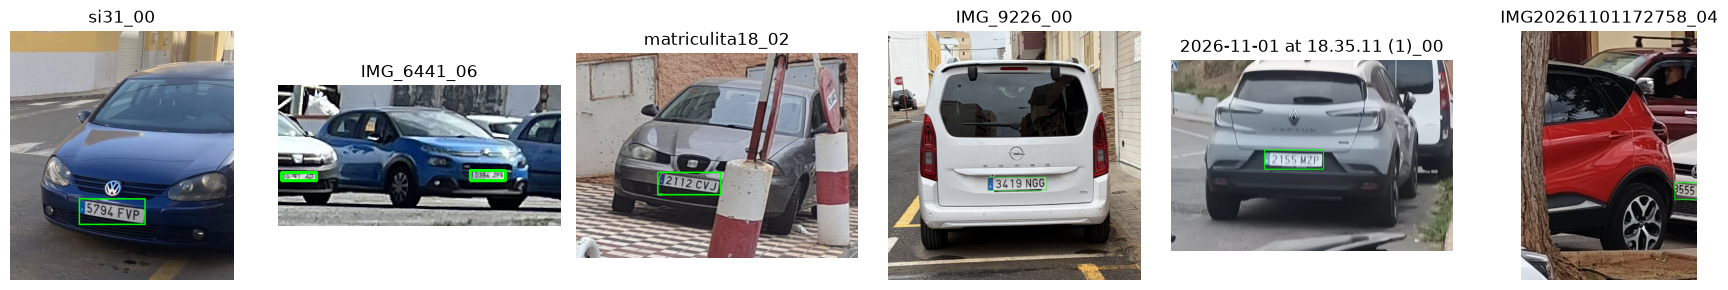

In [19]:
def draw_plates(split, stem):
    image = cv2.imread(str(OUT / split / "images" / f"{stem}.jpg"))
    height, width = image.shape[:2]
    for plate in json.load(open(OUT / split / "annotations" / f"{stem}.json", encoding="utf-8")):
        cx, cy, w, h = plate["rectangle"]
        p1 = (round((cx - w / 2) * width), round((cy - h / 2) * height))
        p2 = (round((cx + w / 2) * width), round((cy + h / 2) * height))
        cv2.rectangle(image, p1, p2, (0, 255, 0), 2)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def show_crops(split="train", n=6, seed=SEED):
    stems = sorted(p.stem for p in (OUT / split / "annotations").iterdir()
                   if json.load(open(p, encoding="utf-8")))
    plt.figure(figsize=(3 * n, 3))
    for i, stem in enumerate(random.Random(seed).sample(stems, n)):
        plt.subplot(1, n, i + 1)
        plt.imshow(draw_plates(split, stem))
        plt.title(stem)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


show_crops()